<a href="https://colab.research.google.com/github/AbdullahAmjad-22/coco-human-pose-estimation/blob/main/coco_human_pose_estimation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import torch
import torchvision
import json
import os
import urllib.request
import zipfile
import random
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision.transforms import functional as F

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# Download COCO annotations
url = "http://images.cocodataset.org/annotations/annotations_trainval2017.zip"
zip_path = "/content/annotations.zip"

if not os.path.exists(zip_path):
    urllib.request.urlretrieve(url, zip_path)

# Extract only the keypoint annotation file
with zipfile.ZipFile(zip_path) as z:
    z.extract(
        "annotations/person_keypoints_train2017.json",
        "/content"
    )

print("Annotations ready!")

Device: cuda
Annotations ready!


In [ ]:
with open(
    "/content/annotations/person_keypoints_train2017.json"
) as f:
    data = json.load(f)

# Keep annotations with at least one labeled keypoint
annotations = [
    a for a in data["annotations"]
    if a["num_keypoints"] > 0
]

# Select images containing labeled people
image_ids = list(dict.fromkeys(a["image_id"] for a in annotations))
random.seed(42)
random.shuffle(image_ids)
image_ids = image_ids[:100]

images = {
    img["id"]: img for img in data["images"]
}

os.makedirs("/content/coco_small", exist_ok=True)

downloaded_ids = set()

for image_id in image_ids:
    info = images[image_id]
    path = f"/content/coco_small/{info['file_name']}"

    try:
        if not os.path.exists(path):
            urllib.request.urlretrieve(info["coco_url"], path)
        downloaded_ids.add(image_id)
    except Exception as e:
        print("Skipped:", info["file_name"], e)

# Keep only annotations for images that downloaded successfully
annotations = [
    a for a in annotations
    if a["image_id"] in downloaded_ids
]

print("Images downloaded:", len(downloaded_ids))
print("Person annotations:", len(annotations))

Images downloaded: 100
Person annotations: 220


In [ ]:
class PoseDataset(Dataset):
    def __init__(self, annotations, images):
        self.annotations = annotations
        self.images = images

        self.image_ids = list(dict.fromkeys(
            a["image_id"] for a in annotations
        ))

        self.groups = {}
        for a in annotations:
            self.groups.setdefault(a["image_id"], []).append(a)

    def __len__(self):
        return len(self.image_ids)

    def __getitem__(self, index):
        image_id = self.image_ids[index]
        info = self.images[image_id]

        path = f"/content/coco_small/{info['file_name']}"
        image = Image.open(path).convert("RGB")
        image = F.to_tensor(image)

        boxes, keypoints, areas = [], [], []

        for a in self.groups[image_id]:
            x, y, w, h = a["bbox"]

            # Ignore invalid bounding boxes
            if w <= 0 or h <= 0:
                continue

            boxes.append([x, y, x + w, y + h])
            keypoints.append(
                np.array(a["keypoints"]).reshape(17, 3)
            )
            areas.append(a["area"])

        target = {
            "boxes": torch.tensor(boxes, dtype=torch.float32),
            "labels": torch.ones(len(boxes), dtype=torch.int64),
            "keypoints": torch.tensor(
                np.array(keypoints), dtype=torch.float32
            ).reshape(-1, 17, 3),
            "image_id": torch.tensor([image_id]),
            "area": torch.tensor(areas, dtype=torch.float32),
            "iscrowd": torch.zeros(len(boxes), dtype=torch.int64)
        }

        return image, target


dataset = PoseDataset(annotations, images)

def collate_fn(batch):
    return tuple(zip(*batch))

loader = DataLoader(
    dataset,
    batch_size=2,
    shuffle=True,
    collate_fn=collate_fn
)

print("Training images:", len(dataset))

Training images: 100


In [ ]:
from torchvision.models.detection import (
    keypointrcnn_resnet50_fpn,
    KeypointRCNN_ResNet50_FPN_Weights
)

weights = KeypointRCNN_ResNet50_FPN_Weights.DEFAULT

model = keypointrcnn_resnet50_fpn(weights=weights)
model = model.to(device)

print("Model loaded!")

Downloading: "https://download.pytorch.org/models/keypointrcnn_resnet50_fpn_coco-fc266e95.pth" to /root/.cache/torch/hub/checkpoints/keypointrcnn_resnet50_fpn_coco-fc266e95.pth


100%|██████████| 226M/226M [00:01<00:00, 175MB/s]


Model loaded!


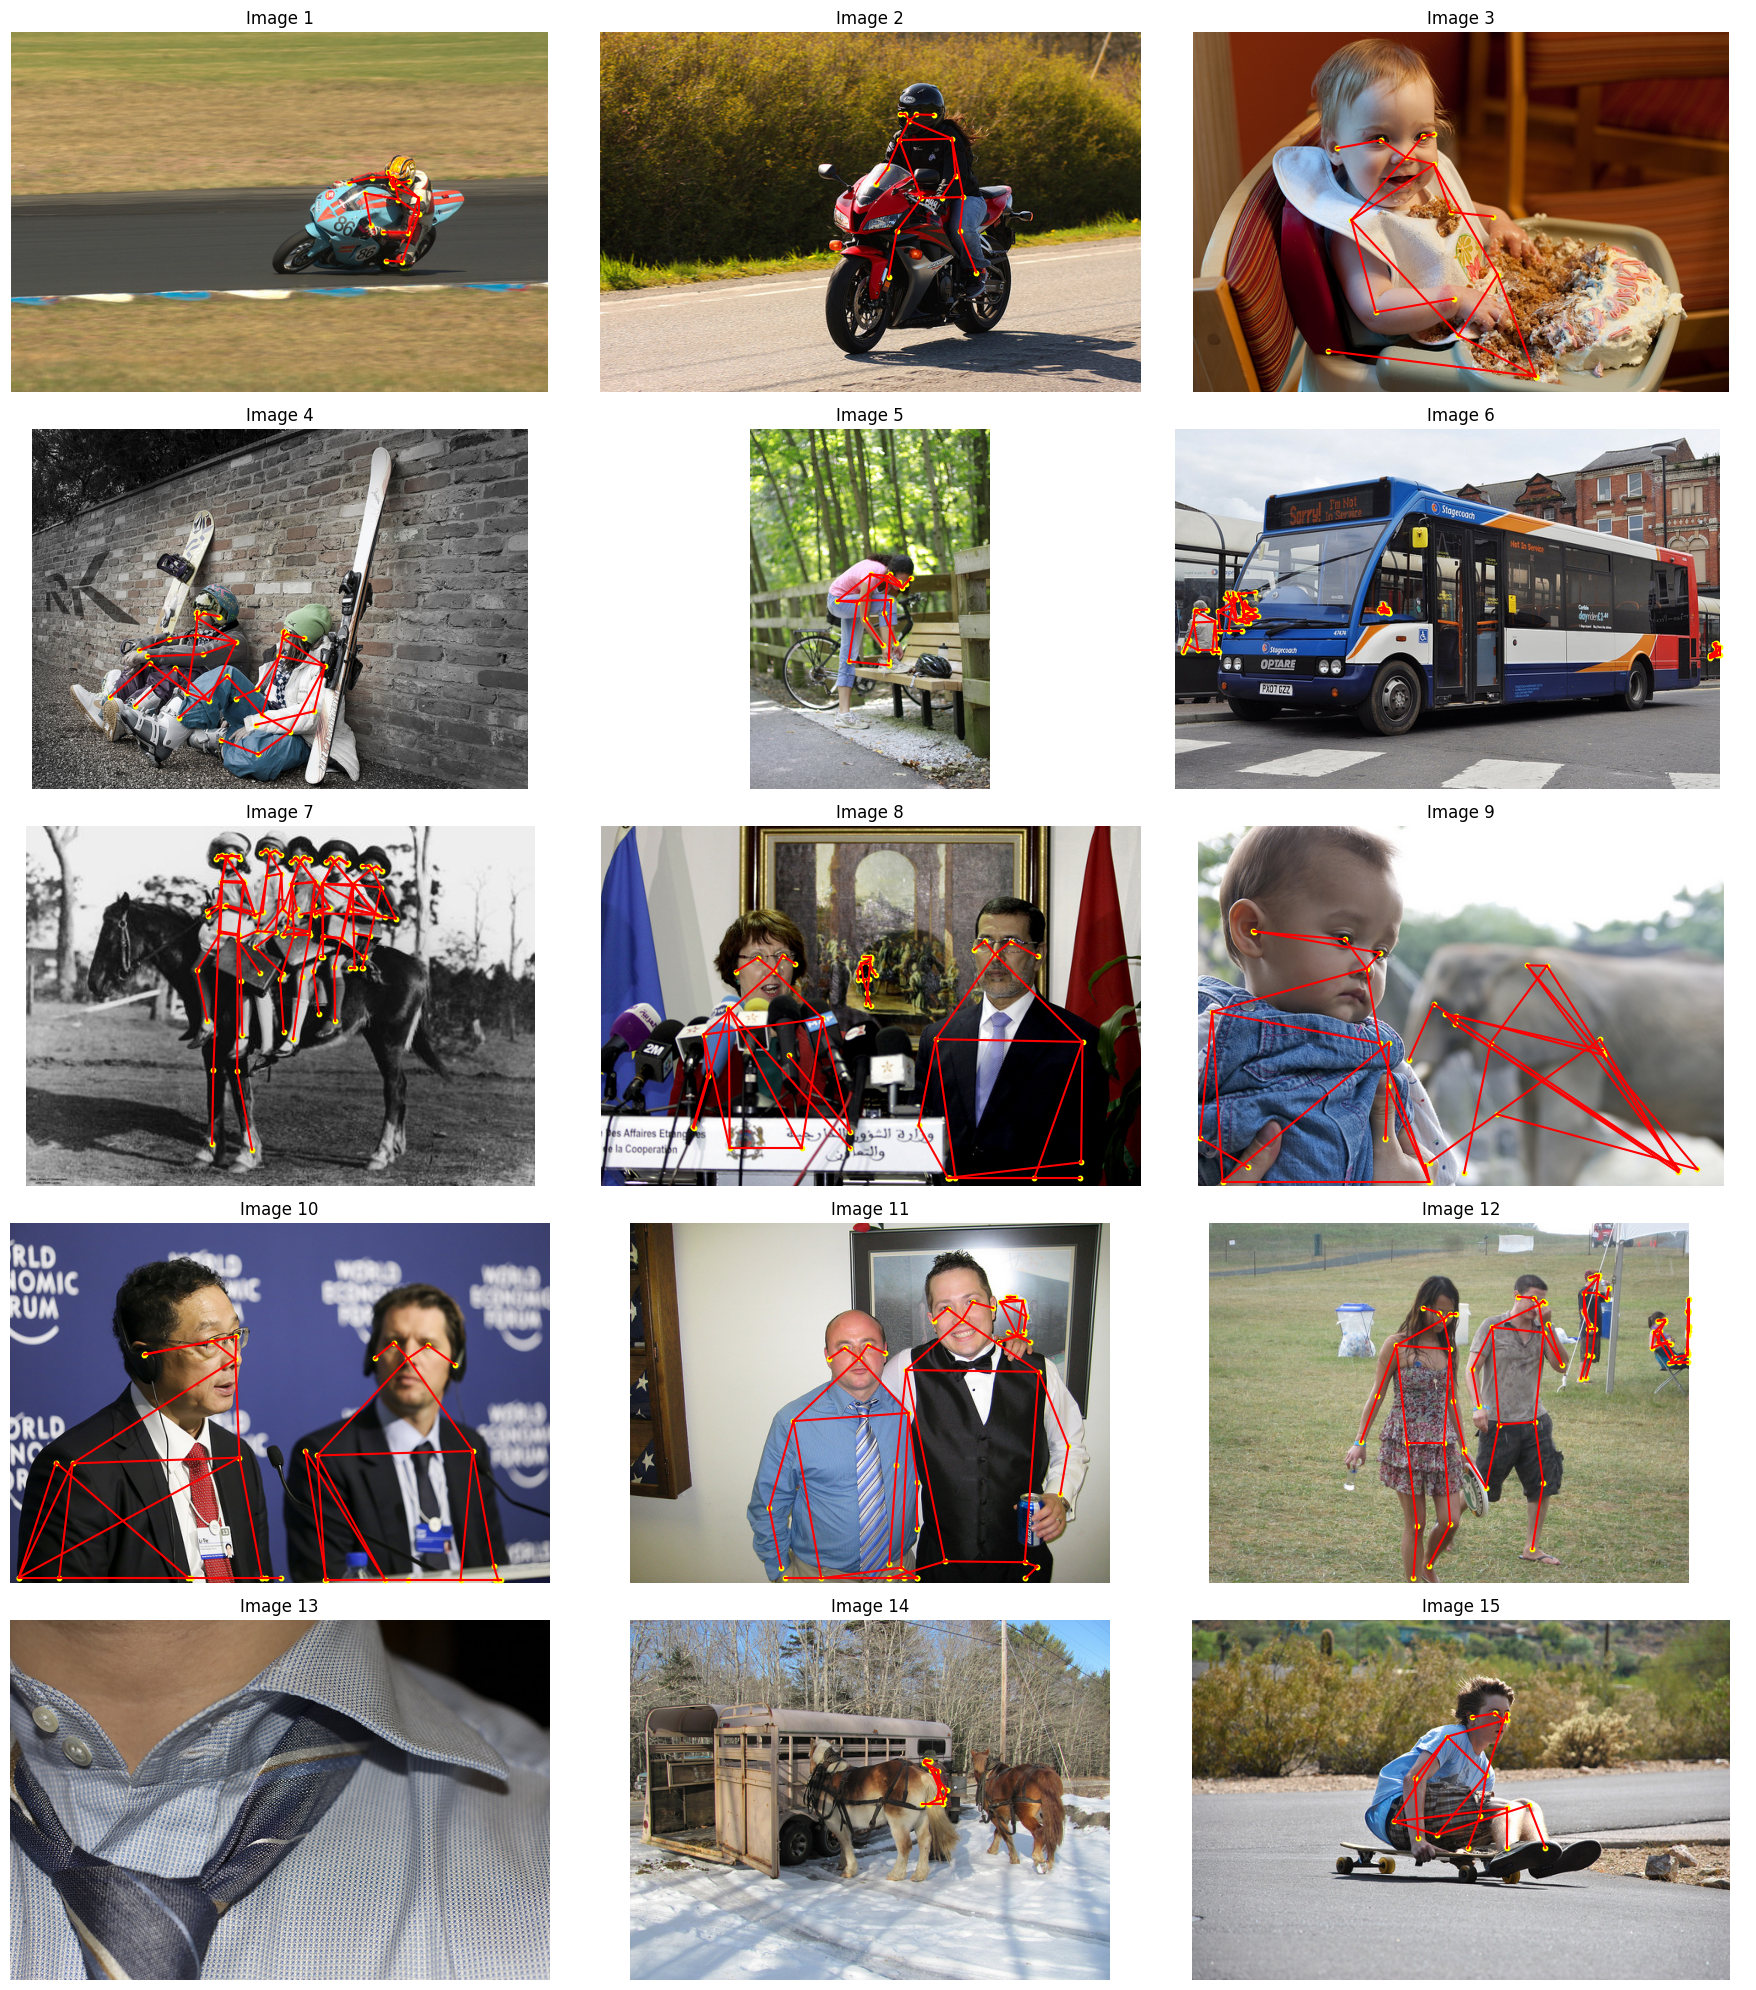

In [ ]:
model.eval()

skeleton = [
    (5, 6), (5, 7), (7, 9), (6, 8), (8, 10),
    (5, 11), (6, 12), (11, 12),
    (11, 13), (13, 15), (12, 14), (14, 16),
    (0, 1), (0, 2), (1, 3), (2, 4),
    (0, 5), (0, 6)
]

plt.figure(figsize=(18, 20))

for i in range(15):
    image, _ = dataset[i]

    with torch.no_grad():
        prediction = model([image.to(device)])[0]

    img = image.permute(1, 2, 0).numpy()

    plt.subplot(5, 3, i + 1)
    plt.imshow(img)

    for j, score in enumerate(prediction["scores"]):
        if score < 0.7:
            continue

        points = prediction["keypoints"][j].cpu().numpy()

        for a, b in skeleton:
            if points[a, 2] > 0.5 and points[b, 2] > 0.5:
                plt.plot(
                    [points[a, 0], points[b, 0]],
                    [points[a, 1], points[b, 1]],
                    "r-",
                    linewidth=1.5
                )

        visible = points[:, 2] > 0.5
        plt.scatter(
            points[visible, 0],
            points[visible, 1],
            c="yellow",
            s=10
        )

    plt.title(f"Image {i + 1}")
    plt.axis("off")

plt.tight_layout()
plt.show()

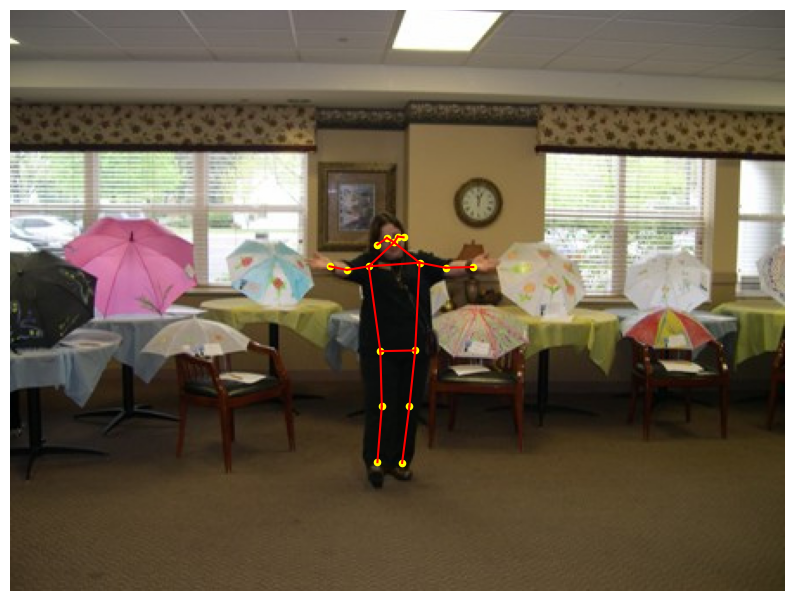

In [ ]:
import matplotlib.pyplot as plt

model.eval()

image, _ = dataset[76]

with torch.no_grad():
    prediction = model([image.to(device)])[0]

# Convert image to a format Matplotlib can display
img = image.permute(1, 2, 0).numpy()

plt.figure(figsize=(10, 8))
plt.imshow(img)

# COCO skeleton connections (17 keypoints)
skeleton = [
    (5, 6), (5, 7), (7, 9), (6, 8), (8, 10),
    (5, 11), (6, 12), (11, 12),
    (11, 13), (13, 15), (12, 14), (14, 16),
    (0, 1), (0, 2), (1, 3), (2, 4),
    (0, 5), (0, 6)
]

for i, score in enumerate(prediction["scores"]):
    if score < 0.7:
        continue

    points = prediction["keypoints"][i].cpu().numpy()

    for a, b in skeleton:
        if points[a, 2] > 0.5 and points[b, 2] > 0.5:
            plt.plot(
                [points[a, 0], points[b, 0]],
                [points[a, 1], points[b, 1]],
                "r-"
            )

    visible = points[:, 2] > 0.5
    plt.scatter(
        points[visible, 0],
        points[visible, 1],
        c="yellow",
        s=20
    )

plt.axis("off")
plt.show()